## 1 - Διάβασμα εικόνων για training

In [6]:
import numpy as np
%pip install opencv-python

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [7]:
import cv2
import os
import numpy as np
import pandas as pd


def load_and_assign_images():
    images = {
        "wearing_glasses": [],
        "not_wearing_glasses": [],
        "long_hair": [],
        "short_hair": [],
        "smiling": [],
        "not_smiling": [],
        "beard": [],
        "not_beard": [],
        "woman": [],
        "man": []
    }

    categories = pd.read_csv("classes.csv")
    root = "faces_dataset"
    count = 0

    for i in range(1, 41):
        subject_folder = os.path.join(root, f"s{i}")
        for filename in sorted(os.listdir(subject_folder)):
            path = os.path.join(subject_folder, filename)

            img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

            if img is None:
                print("Could not read:", path)
                continue

            img_np = np.asarray(img, dtype=np.float32)
            flat = img_np.flatten() / 255.0

            row = categories.iloc[count]

            if row["wearing_glasses"] == 1:
                images["wearing_glasses"].append(flat)
            else:
                images["not_wearing_glasses"].append(flat)
            if row["long_hair"] == 1:
                images["long_hair"].append(flat)
            else:
                images["short_hair"].append(flat)
            if row["smiling"] == 1:
                images["smiling"].append(flat)
            else:
                images["not_smiling"].append(flat)

            if row["beard"] == 1:
                images["beard"].append(flat)
            else:
                images["not_beard"].append(flat)

            if row["woman"] == 1:
                images["woman"].append(flat)
            else:
                images["man"].append(flat)
            count += 1
    for key in images:
        images[key] = np.array(images[key])
    return images

def split_train_test(images, train_ratio=0.8, seed=42):
    rng = np.random.default_rng(seed)

    train_images = {}
    test_images = {}

    for label, X in images.items():
        X = np.asarray(X)

        n = len(X)
        indices = np.arange(n)
        rng.shuffle(indices)

        split_idx = int(train_ratio * n)

        train_idx = indices[:split_idx]
        test_idx = indices[split_idx:]

        train_images[label] = X[train_idx]
        test_images[label] = X[test_idx]

    return train_images, test_images

images = load_and_assign_images()
# for key in images:
#     print(f"{key}: {images[key].shape}")

train_images, test_images = split_train_test(images, train_ratio=0.8)
# for key in images.keys():
#     print(f"{key}")
#     print("  train:", train_images[key].shape)
#     print("  test: ", test_images[key].shape)

binary_classification_pairs = [
    ("wearing_glasses", "not_wearing_glasses"),
    ("long_hair", "short_hair"),
    ("smiling", "not_smiling"),
    ("beard", "not_beard"),
    ("woman", "man")
]



## LDA

checking pair: ('wearing_glasses', 'not_wearing_glasses')


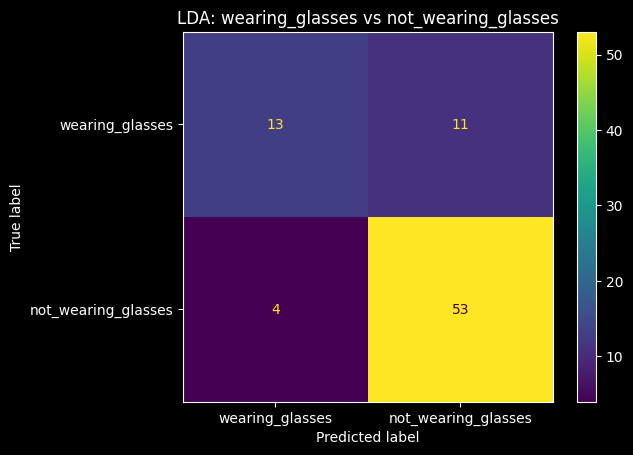

checking pair: ('long_hair', 'short_hair')


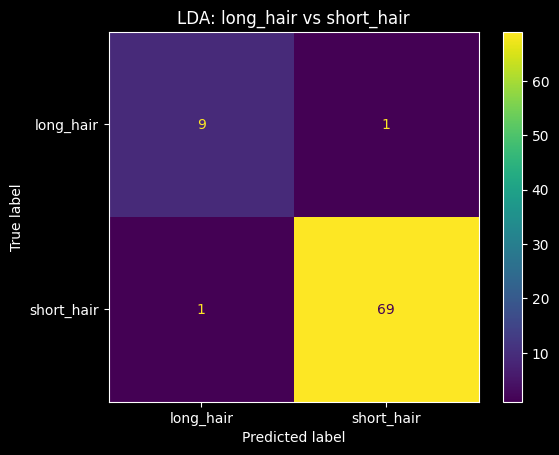

checking pair: ('smiling', 'not_smiling')


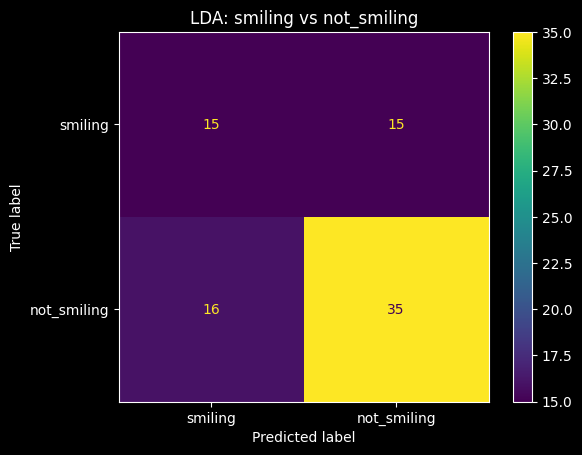

checking pair: ('beard', 'not_beard')


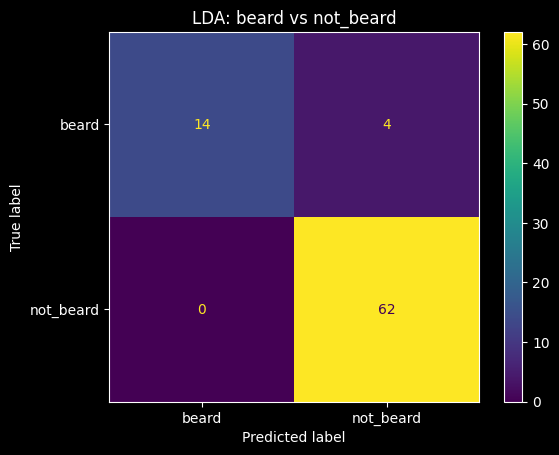

checking pair: ('woman', 'man')


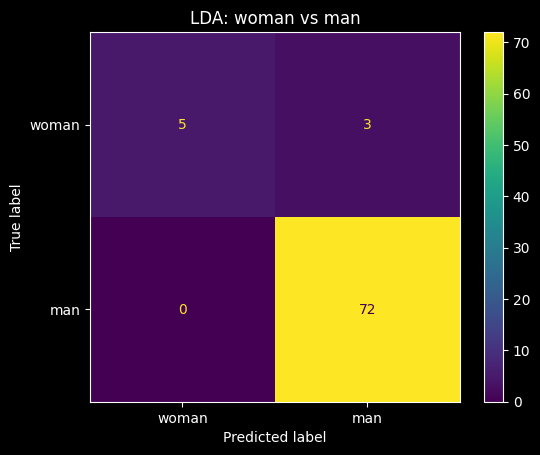

,wearing_glasses,long_hair,smiling,beard,woman
,not_wearing_glasses,short_hair,not_smiling,not_beard,man
correct,66.000000,78.000,50.000000,76.00,77.0000
total,81.000000,80.000,81.000000,80.00,80.0000
accuracy,0.814815,0.975,0.617284,0.95,0.9625


In [5]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

test_results = {}
def train_lda_binary_regularized(X1, X2, reg=1e-3):
    m1 = X1.mean(axis=0)
    m2 = X2.mean(axis=0)

    X1_centered = X1 - m1
    X2_centered = X2 - m2

    S1 = X1_centered.T @ X1_centered
    S2 = X2_centered.T @ X2_centered
    Sw = S1 + S2

    # Regularization, because Sw is probably singular for image vectors
    Sw_reg = Sw + reg * np.eye(Sw.shape[0])

    w = np.linalg.solve(Sw_reg, m1 - m2)

    projected_m1 = m1 @ w
    projected_m2 = m2 @ w

    return w, projected_m1, projected_m2

def classify_x_lda(x, w, projected_m1, projected_m2, label1, label2):
    z = x @ w

    dist1 = abs(z - projected_m1)
    dist2 = abs(z - projected_m2)

    if dist1 < dist2:
        return label1
    else:
        return label2

for label1, label2 in binary_classification_pairs:
    print("checking pair:", (label1, label2))

    w, pm1, pm2 = train_lda_binary_regularized(train_images[label1], train_images[label2])

    X_test = np.vstack([test_images[label1], test_images[label2]])
    y_test = np.array([label1] * len(test_images[label1]) + [label2] * len(test_images[label2]))

    y_pred = np.array([classify_x_lda(x, w, pm1, pm2, label1, label2) for x in X_test])

    correct = np.sum(y_pred == y_test)
    total = len(y_test)
    cm = confusion_matrix(y_test, y_pred, labels=[label1, label2])

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[label1, label2])
    disp.plot()
    plt.title(f"LDA: {label1} vs {label2}")
    plt.show()

    test_results[(label1, label2)] = {
        "correct": int(correct),
        "total": int(total),
        "accuracy": correct / total if total > 0 else 0
    }

test = pd.DataFrame(test_results)
display(test)

## PCA

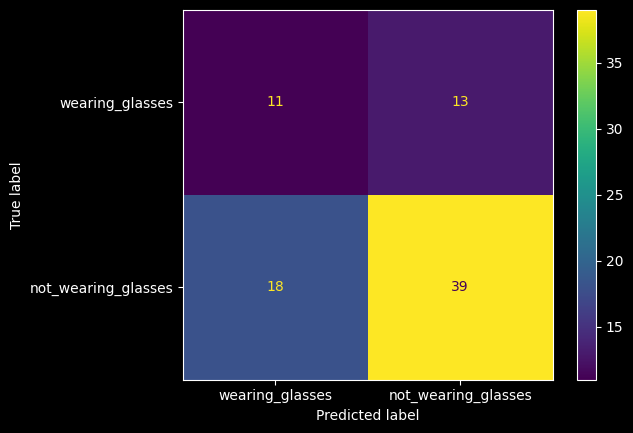

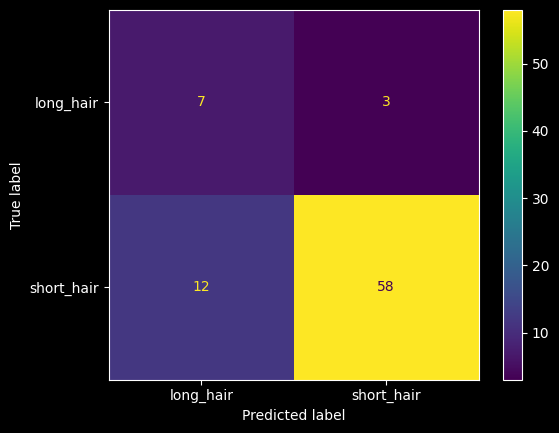

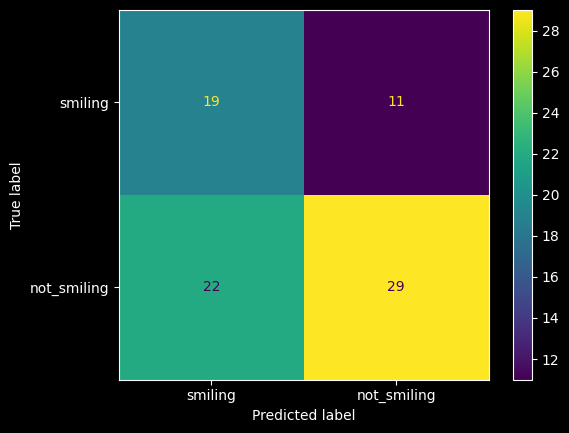

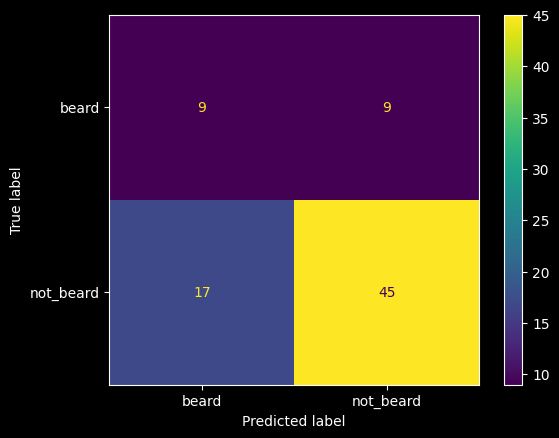

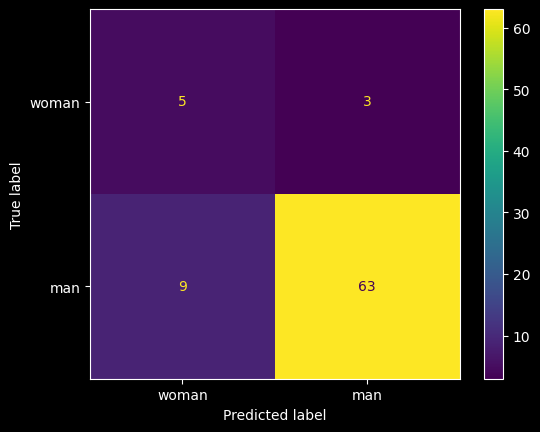

,wearing_glasses,long_hair,smiling,beard,woman
,not_wearing_glasses,short_hair,not_smiling,not_beard,man
correct,50.000000,65.0000,48.000000,54.000,68.00
total,81.000000,80.0000,81.000000,80.000,80.00
accuracy,0.617284,0.8125,0.592593,0.675,0.85


In [9]:
n_components=100
def train_pca(X_train, n_components=100):
    n_components = min(n_components, X_train.shape[1], X_train.shape[0])
    mean = X_train.mean(axis=0)
    Xc = X_train - mean
    U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    components = Vt[:n_components]
    return mean, components


def project_pca(X, mean, components):
    return (X - mean) @ components.T


def get_means_of_projections(X1_proj, X2_proj):
    return X1_proj.mean(axis=0), X2_proj.mean(axis=0)


def classify_using_pca(x_proj, m1, m2, label1, label2, norm_type=2):
    d1 = np.linalg.norm(x_proj - m1, ord=norm_type)
    d2 = np.linalg.norm(x_proj - m2, ord=norm_type)

    return label1 if d1 < d2 else label2


pca_results = {}

for label1, label2 in binary_classification_pairs:
    X1_train, X2_train = train_images[label1], train_images[label2]
    X1_test, X2_test = test_images[label1], test_images[label2]

    X_train = np.vstack([X1_train, X2_train])
    X_test = np.vstack([X1_test, X2_test])
    y_test = np.array([label1] * len(X1_test) + [label2] * len(X2_test))

    mean, components = train_pca(X_train, n_components=n_components)

    X1_train_proj = project_pca(X1_train, mean, components)
    X2_train_proj = project_pca(X2_train, mean, components)
    X_test_proj = project_pca(X_test, mean, components)

    m1_proj, m2_proj = get_means_of_projections(X1_train_proj, X2_train_proj)

    y_pred = np.array([classify_using_pca(x, m1_proj, m2_proj, label1, label2) for x in X_test_proj])
    accuracy = np.mean(y_pred == y_test)

    cm = confusion_matrix(y_test, y_pred, labels=[label1, label2])

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[label1, label2])
    disp.plot()
    plt.show()

    correct = np.sum(y_pred == y_test)
    total = len(y_test)
    accuracy = correct / total if total > 0 else 0
    pca_results[(label1, label2)] = {
        "correct": int(correct),
        "total": int(total),
        "accuracy": correct / total if total > 0 else 0
    }
results = pd.DataFrame(pca_results)
display(results)

### CCA

In [10]:
def load_xy_arrays(root="faces_dataset", csv_path="classes.csv"):
    X_all, Y_all = [], []
    categories = pd.read_csv(csv_path)
    attribute_cols = ["wearing_glasses", "long_hair", "smiling", "beard", "woman"]
    count = 0

    for i in range(1, 41):
        subject_folder = os.path.join(root, f"s{i}")
        for filename in sorted(os.listdir(subject_folder)):
            path = os.path.join(subject_folder, filename)
            img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
            if img is None:
                print("Could not read:", path)
                continue
            x = img.astype(np.float32).flatten() / 255.0
            y = categories.loc[count, attribute_cols].to_numpy(dtype=np.float32)
            X_all.append(x)
            Y_all.append(y)
            count += 1
    return np.array(X_all), np.array(Y_all)

def split_xy(X, Y, train_ratio=0.8, seed=42):
    rng = np.random.default_rng(seed)

    n = len(X)
    indices = np.arange(n)
    rng.shuffle(indices)

    split = int(train_ratio * n)

    train_idx = indices[:split]
    test_idx = indices[split:]

    X_train, X_test = X[train_idx], X[test_idx]
    Y_train, Y_test = Y[train_idx], Y[test_idx]

    return X_train, X_test, Y_train, Y_test

X_all, Y_all = load_xy_arrays()
X_train, X_test, Y_train, Y_test = split_xy(X_all, Y_all, train_ratio=0.8)

def train_cca(X, Y, n_components=5, reg=1e-3):
    X_mean, Y_mean = X.mean(axis=0), Y.mean(axis=0)
    Xc, Yc = X - X_mean, Y - Y_mean

    n = X.shape[0]

    Sxx = (Xc.T @ Xc) / (n - 1) + reg * np.eye(Xc.shape[1])
    Syy = (Yc.T @ Yc) / (n - 1) + reg * np.eye(Yc.shape[1])
    Sxy = (Xc.T @ Yc) / (n - 1)

    invSxx = np.linalg.pinv(Sxx)
    invSyy = np.linalg.pinv(Syy)

    M = invSxx @ Sxy @ invSyy @ Sxy.T

    eigvals, eigvecs = np.linalg.eig(M)

    order = np.argsort(eigvals.real)[::-1]
    Wx = eigvecs[:, order[:n_components]].real

    return X_mean, Y_mean, Wx

def project_cca_x(X, X_mean, Wx):
    return (X - X_mean) @ Wx

n_pca_components = 100
n_cca_components = 5

pca_mean, pca_components = train_pca(X_train, n_components=n_pca_components)

X_train_pca = project_pca(X_train, pca_mean, pca_components)
X_test_pca = project_pca(X_test, pca_mean, pca_components)

cca_x_mean, cca_y_mean, Wx = train_cca(
    X_train_pca,
    Y_train,
    n_components=n_cca_components,
    reg=1e-3
)

X_train_cca = project_cca_x(X_train_pca, cca_x_mean, Wx)
X_test_cca = project_cca_x(X_test_pca, cca_x_mean, Wx)



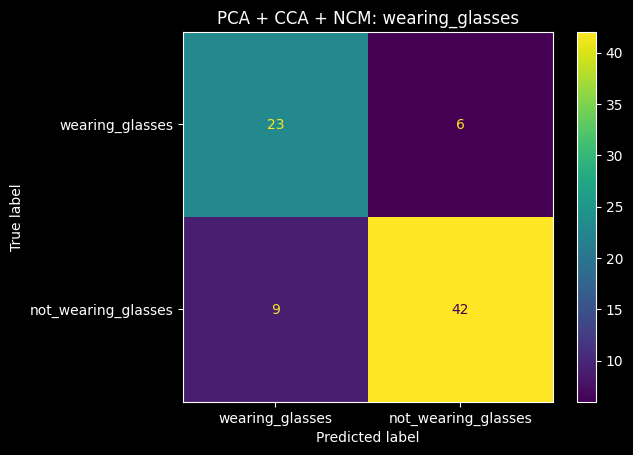

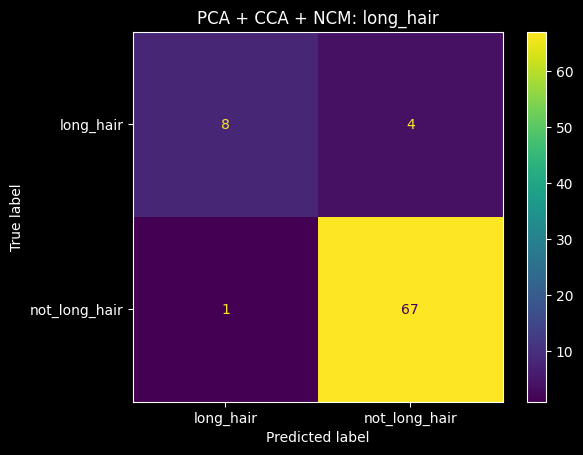

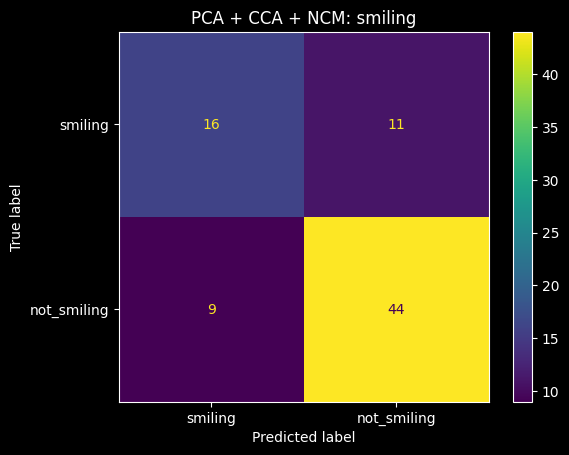

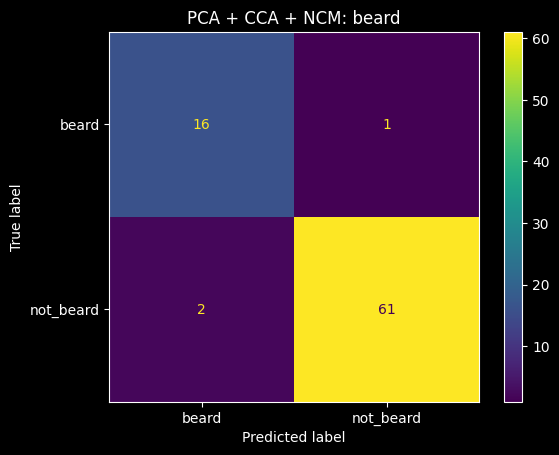

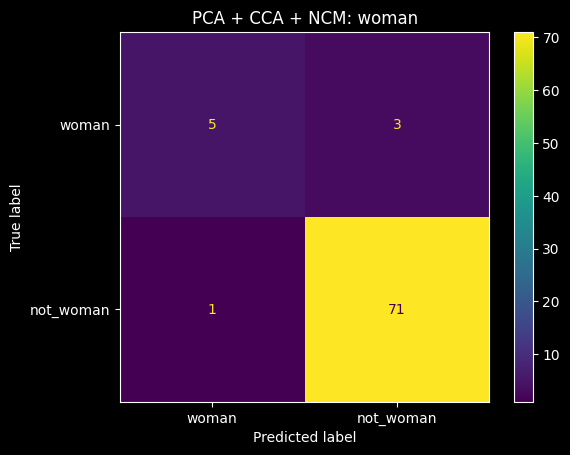

,attribute,correct,total,accuracy
0,wearing_glasses,65,80,0.8125
1,long_hair,75,80,0.9375
2,smiling,60,80,0.7500
3,beard,77,80,0.9625
4,woman,76,80,0.9500


In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd

attribute_cols = ["wearing_glasses", "long_hair", "smiling", "beard", "woman"]
cca_results = {}

for j, attr in enumerate(attribute_cols):
    y_train_attr = Y_train[:, j]
    y_test_attr = Y_test[:, j]

    X_pos_train = X_train_cca[y_train_attr == 1]
    X_neg_train = X_train_cca[y_train_attr == 0]

    m_pos = X_pos_train.mean(axis=0)
    m_neg = X_neg_train.mean(axis=0)

    y_pred = []

    for x in X_test_cca:
        d_pos = np.linalg.norm(x - m_pos, ord=2)
        d_neg = np.linalg.norm(x - m_neg, ord=2)

        pred = 1 if d_pos < d_neg else 0
        y_pred.append(pred)

    y_pred = np.array(y_pred)

    correct = np.sum(y_pred == y_test_attr)
    total = len(y_test_attr)
    accuracy = correct / total if total > 0 else 0

    cm = confusion_matrix(y_test_attr, y_pred, labels=[1, 0])

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[attr, f"not_{attr}"])
    disp.plot()
    plt.title(f"PCA + CCA + NCM: {attr}")
    plt.show()

    cca_results[attr] = {
        "correct": int(correct),
        "total": int(total),
        "accuracy": float(accuracy),
        "confusion_matrix": cm
    }

results = pd.DataFrame([
    {
        "attribute": attr,
        "correct": values["correct"],
        "total": values["total"],
        "accuracy": values["accuracy"]
    }
    for attr, values in cca_results.items()
])

display(results)